# Partially ordered traces from position-resolved edges

**EXPLORATORY** (CLAUDE.md §2: exempt from the TDD gate).

One **trace** per example (prompt). Nothing is aggregated over positions: the same feature at two token positions
is two events.

- **Event:** a node instance `(site, token, feature)` of one example that passes `NODE_FILTER`. `feature = -1` is
  the SAE error node, an event like any other.
- **Relation:** `e → e'` when the edge store holds a direct-effect edge from `e` into `e'`
  (Marks et al., arXiv:2403.19647, `src/attribution/positional_edges.py`), and that edge passes the optional
  `|edge_ie| > EDGE_IE_THRESHOLD`.
- **Partial order:** the reflexive-transitive closure of the relation. Every edge goes to a strictly later site, so
  the relation is acyclic and the closure is a partial order. Two events are **concurrent** when no path joins them.
- **Hasse diagram:** the transitive reduction (covering relation). An edge it drops is still a measured direct
  effect; the order already implies it.

**What the edge store can answer.** The edge run computes edges only *into* the destinations of its method. Every
upstream node is kept as a source. So `NODE_FILTER` must select a subset of that method's destinations. Events
outside it would have no incoming edges, so they are dropped, with a warning. `IMPLICIT_SOURCES = True` adds the
sources of surviving edges that the filter rejected. That is a circuit-building choice, so it is off by default.
`INCLUDE_METRIC` adds the metric `y` as the top event of every trace.


In [1]:
import json
import os
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
from IPython.display import display
from matplotlib.lines import Line2D

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)                      # output paths are repo-relative
sys.path.insert(0, str(ROOT))
from src.selection.destinations import destination_masks

NODE_RUN = Path("data/outputs/nounpp/attributions/nodes/default")
METHOD = "marks"                    # an edge store under .../edges/<counterfactual>/<METHOD>
EDGE_IE_THRESHOLD = None            # None = keep every stored edge; else keep |edge_ie| > this
IMPLICIT_SOURCES = False            # add filtered-out sources of surviving edges as events
INCLUDE_METRIC = True               # the metric y as the top event of every trace
MAX_EXAMPLES = 200                  # traces to build (None = all); sample fixed by SEED
SEED = 42
DECODE_TOKENS = True                # label positions with the tokenizer's strings (loads it)


def NODE_FILTER(raw, n_examples, method_spec):
    # Bool per node row: is it an event? Default: the edge run's own destinations. Replace with any rule that
    # selects a subset of them.
    return destination_masks(raw, {"m": method_spec}, n_examples)["m"].to_numpy()


## Load the node run and its edge store

In [2]:
EDGE_DIR = NODE_RUN.parent.parent / "edges" / NODE_RUN.name / METHOD
node_manifest = json.loads((NODE_RUN / "manifest.json").read_text())
edge_manifest = json.loads((EDGE_DIR / "manifest.json").read_text())
method_spec = edge_manifest["params"]["method"]
if edge_manifest["params"]["node_run"]["params"] != node_manifest["params"]:
    raise ValueError(f"{EDGE_DIR} was computed from a different node run than {NODE_RUN}.")

hive = ds.dataset(NODE_RUN / "nodes", format="parquet", partitioning="hive")
raw = (hive.to_table(columns=["example_idx", "site_ordinal", "token_idx", "token_id", "feature_idx", "attribution"])
       .to_pandas()
       .astype({"example_idx": "int32", "site_ordinal": "int16", "token_idx": "int16", "token_id": "int32",
                "feature_idx": "int32", "attribution": "float32"}))
N = node_manifest.get("n_examples", raw["example_idx"].nunique())   # denominator of every mean
first = int(raw["example_idx"].iloc[0])
site_name = {int(r.site_ordinal): r.kind if r.kind == "embed" else f"{r.kind}{r.block}"
             for r in hive.to_table(columns=["site_ordinal", "kind", "block"], filter=ds.field("example_idx") == first)
             .to_pandas().drop_duplicates("site_ordinal").itertuples()}

all_ids = np.unique(raw["example_idx"].to_numpy())
ids = (np.sort(np.random.default_rng(SEED).choice(all_ids, MAX_EXAMPLES, replace=False))
       if MAX_EXAMPLES is not None and MAX_EXAMPLES < len(all_ids) else all_ids)
print(f"{len(raw):,} node rows over {len(all_ids):,} examples; building {len(ids):,} traces; method {method_spec}")


17,707,371 node rows over 1,614 examples; building 200 traces; method {'rule': 'marks', 'threshold': 0.1, 'aggregation': 'sum'}


## Events and relation

The filter runs over **all** examples, because alphabet rules such as `marks` average over them. Only the sampled
traces are built after that.

In [3]:
is_event = np.asarray(NODE_FILTER(raw, N, method_spec), dtype=bool)
is_dest = destination_masks(raw, {"m": method_spec}, N)["m"].to_numpy()
if (outside := is_event & ~is_dest).any():
    print(f"WARNING: {outside.sum():,} events are not destinations of {METHOD!r} and have no incoming edges; dropped.")
    is_event &= is_dest

NODE = ["site_ordinal", "token_idx", "feature_idx"]
events = raw.loc[is_event & raw["example_idx"].isin(ids).to_numpy()].reset_index(drop=True)
token_ids = raw.loc[raw["example_idx"].isin(ids)].drop_duplicates(["example_idx", "token_idx"]) \
    .set_index(["example_idx", "token_idx"])["token_id"]
del raw, is_event, is_dest

edges = (ds.dataset(EDGE_DIR / "edges", format="parquet", partitioning="hive")
         .to_table(filter=ds.field("example_idx").isin(ids.tolist())).to_pandas()
         .astype({"example_idx": "int32", "src_ordinal": "int16", "src_token": "int16", "src_feature": "int32",
                  "dst_ordinal": "int16", "dst_token": "int16", "dst_feature": "int32", "edge_ie": "float32"}))
n_stored = len(edges)
if EDGE_IE_THRESHOLD is not None:
    edges = edges[edges["edge_ie"].abs() > EDGE_IE_THRESHOLD]

event_index = pd.MultiIndex.from_frame(events[["example_idx", *NODE]])
def among_events(side):
    cols = [f"{side}_ordinal", f"{side}_token", f"{side}_feature"]
    return pd.MultiIndex.from_frame(edges[["example_idx", *cols]]).isin(event_index)

into_metric = (edges["dst_ordinal"] == -1).to_numpy()
keep = np.where(into_metric, INCLUDE_METRIC, among_events("dst"))
if not IMPLICIT_SOURCES:
    keep &= among_events("src")
relation = edges[keep].reset_index(drop=True)
print(f"{len(events):,} events; {n_stored:,} stored edges -> {len(relation):,} in the relation "
      f"(|edge_ie| > {EDGE_IE_THRESHOLD}, implicit sources {IMPLICIT_SOURCES}, metric {INCLUDE_METRIC})")


19,692 events; 5,024,211 stored edges -> 80,734 in the relation (|edge_ie| > None, implicit sources False, metric True)


## Build the traces

`traces[ex]` is the relation as a DAG (`edge_ie` on each edge, node IE and token on each event). `hasse[ex]` is its
transitive reduction. Per-trace numbers:

- **comparable:** event pairs ordered by the partial order.
- **density:** comparable pairs as a share of all pairs; 0 means no order at all, 1 means a chain.
- **height:** the longest chain, counted in events.
- **isolated:** events with no relation to any other event.
- **cross-token:** Hasse edges whose two events sit at different positions.

In [4]:
METRIC = (-1, -1, -1)
ev_by = dict(tuple(events.groupby("example_idx", sort=False)))
rel_by = dict(tuple(relation.groupby("example_idx", sort=False)))


def trace_graph(ex):
    g = nx.DiGraph()
    for r in ev_by.get(ex, events.iloc[:0]).itertuples(index=False):
        g.add_node((r.site_ordinal, r.token_idx, r.feature_idx), ie=float(r.attribution), implicit=False)
    if INCLUDE_METRIC:
        g.add_node(METRIC, ie=np.nan, implicit=False)
    for r in rel_by.get(ex, relation.iloc[:0]).itertuples(index=False):
        u, v = (r.src_ordinal, r.src_token, r.src_feature), (r.dst_ordinal, r.dst_token, r.dst_feature)
        if u not in g:                                   # only reachable with IMPLICIT_SOURCES
            g.add_node(u, ie=np.nan, implicit=True)
        g.add_edge(u, v, edge_ie=float(r.edge_ie))
    assert nx.is_directed_acyclic_graph(g), f"example {ex}: relation has a cycle"
    return g


def reduction(g):
    h = nx.transitive_reduction(g)
    h.add_nodes_from(g.nodes(data=True))
    nx.set_edge_attributes(h, {e: g.edges[e]["edge_ie"] for e in h.edges}, "edge_ie")
    return h


traces = {int(ex): trace_graph(int(ex)) for ex in ids}
hasse = {ex: reduction(g) for ex, g in traces.items()}

rows = []
for ex, g in traces.items():
    n = g.number_of_nodes()
    comparable = sum(len(nx.descendants(g, u)) for u in g)
    rows.append({"example_idx": ex, "events": n, "tokens": len({u[1] for u in g if u != METRIC}),
                 "relation": g.number_of_edges(), "hasse": hasse[ex].number_of_edges(), "comparable": comparable,
                 "density": comparable / (n * (n - 1) / 2) if n > 1 else np.nan,
                 "height": nx.dag_longest_path_length(g) + 1 if n else 0,
                 "isolated": sum(1 for u in g if g.degree(u) == 0),
                 "cross_token": sum(1 for u, v in hasse[ex].edges if v != METRIC and u[1] != v[1])})
summary = pd.DataFrame(rows).set_index("example_idx")
display(summary.describe().T.round(3))


,count,mean,std,min,25%,50%,75%,max
events,200.0,99.460,7.701,78.000,94.000,99.000,105.000,116.000
tokens,200.0,4.050,0.218,4.000,4.000,4.000,4.000,5.000
relation,200.0,403.670,106.882,214.000,316.750,399.500,482.250,670.000
hasse,200.0,295.020,67.834,157.000,242.000,294.000,344.250,457.000
comparable,200.0,2442.190,562.149,1315.000,2025.750,2459.000,2822.750,3841.000
density,200.0,0.496,0.088,0.345,0.411,0.524,0.582,0.623
height,200.0,14.000,0.000,14.000,14.000,14.000,14.000,14.000
isolated,200.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
cross_token,200.0,101.130,22.752,44.000,81.000,106.000,117.250,156.000


## One trace as a Hasse diagram

Columns are token positions, so tokens stay visibly separate. Rows are sites in execution order. Features that
share a (position, site) cell sit side by side. Only attention edges cross columns. Each edge points to the event
it causes.

- Edge colour and line style give the sign: blue and solid for positive, red and dashed for negative. Width scales
  with |edge IE|.
- Circles are features and squares are SAE error nodes. A hollow mark is an implicit source.
- The number on a node is its feature index (ε for an error node).

Token strings unavailable (pythia-70m-deduped is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token having permission to this repo either by logging in with `hf auth login` or by passing `token=<your_token>`); showing token ids.


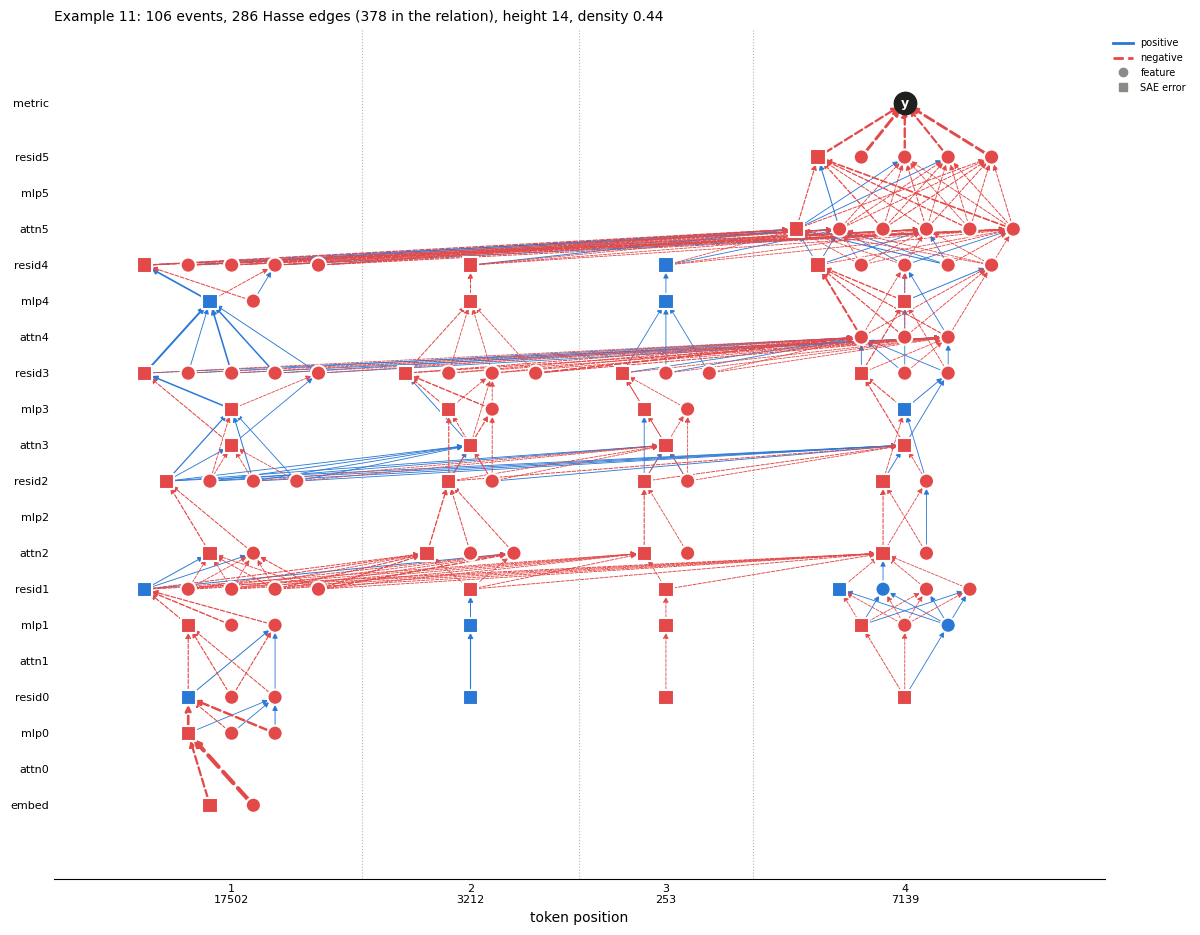

In [5]:
EXAMPLE = int(ids[0])        # any id in `traces`
LABEL_MAX = 80               # hide feature labels above this many events
POS, NEG, NEUTRAL, INK, MUTED = "#2a78d6", "#e34948", "#8a8a86", "#1f1f1d", "#b5b4ae"

decode = lambda tid: str(tid)
if DECODE_TOKENS:
    try:
        from transformers import AutoTokenizer
        from src.models.suites import build_suite
        tok = AutoTokenizer.from_pretrained(build_suite(node_manifest["params"]["suite"]["name"]).model_name)
        decode = lambda tid: repr(tok.decode([int(tid)]))
    except Exception as e:                                  # labels only; fall back to ids
        print(f"Token strings unavailable ({e}); showing token ids.")


def hasse_layout(h, gap=1.0):
    cells = defaultdict(list)
    for u in h:
        if u != METRIC:
            cells[(u[1], u[0])].append(u)
    tokens = sorted({t for t, _ in cells})
    width = {t: max(len(v) for (tt, _), v in cells.items() if tt == t) for t in tokens}
    left, x = {}, 0.0
    for t in tokens:
        left[t], x = x, x + width[t] + gap
    pos = {}
    for (t, _), us in cells.items():
        start = left[t] + (width[t] - len(us)) / 2 + 0.5
        for i, u in enumerate(sorted(us, key=lambda u: u[2])):
            pos[u] = (start + i, u[0])
    if METRIC in h:
        last = tokens[-1] if tokens else 0
        pos[METRIC] = (left.get(last, 0) + width.get(last, 1) / 2, max([u[0] for u in h], default=0) + 1.5)
    return pos, tokens, left, width


def draw_hasse(h, ex, ax=None):
    pos, tokens, left, width = hasse_layout(h)
    if ax is None:
        _, ax = plt.subplots(figsize=(max(6, 0.55 * (sum(width.values()) + len(tokens))),
                                      max(4, 0.45 * (max(site_name, default=0) + 3))))
    for t in tokens[1:]:
        ax.axvline(left[t] - 0.5, color=MUTED, lw=0.8, ls=":", zorder=0)

    ies = np.array([abs(d["edge_ie"]) for *_, d in h.edges(data=True)]) if h.number_of_edges() else np.array([1.0])
    scale = ies.max() or 1.0
    for sign, color, style in ((1, POS, "solid"), (-1, NEG, "dashed")):
        es = [(u, v) for u, v, d in h.edges(data=True) if np.sign(d["edge_ie"]) == sign]
        nx.draw_networkx_edges(h, pos, edgelist=es, ax=ax, edge_color=color, style=style, arrows=True,
                               arrowstyle="-|>", arrowsize=8, node_size=120,
                               width=[0.6 + 2.4 * abs(h.edges[e]["edge_ie"]) / scale for e in es])

    for shape, is_err in (("o", False), ("s", True)):
        us = [u for u in h if u != METRIC and (u[2] == -1) == is_err]
        face = [MUTED if h.nodes[u]["implicit"] else POS if h.nodes[u]["ie"] > 0 else NEG for u in us]
        nx.draw_networkx_nodes(h, pos, nodelist=us, ax=ax, node_shape=shape, node_size=120, node_color=face,
                               edgecolors="white", linewidths=1.5)
        hollow = [u for u in us if h.nodes[u]["implicit"]]
        nx.draw_networkx_nodes(h, pos, nodelist=hollow, ax=ax, node_shape=shape, node_size=120,
                               node_color="white", edgecolors=NEUTRAL, linewidths=1.5)
    if METRIC in h:
        nx.draw_networkx_nodes(h, pos, nodelist=[METRIC], ax=ax, node_size=260, node_color=INK)
        ax.annotate("y", pos[METRIC], color="white", ha="center", va="center", fontsize=9, weight="bold")
    if h.number_of_nodes() <= LABEL_MAX:
        for u in h:
            if u != METRIC:
                ax.annotate("ε" if u[2] == -1 else str(u[2]), pos[u], xytext=(6, -9), textcoords="offset points",
                            ha="left", fontsize=6, color=INK)

    sites = sorted(site_name)
    ax.set_yticks(sites + ([pos[METRIC][1]] if METRIC in h else []))
    ax.set_yticklabels([site_name[s] for s in sites] + (["metric"] if METRIC in h else []), fontsize=8)
    ax.set_xticks([left[t] + width[t] / 2 for t in tokens])
    ax.set_xticklabels([f"{t}\n{decode(token_ids.loc[(ex, t)])}" for t in tokens], fontsize=8)
    ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.set_xlabel("token position")
    s = summary.loc[ex]
    ax.set_title(f"Example {ex}: {int(s.events)} events, {int(s.hasse)} Hasse edges "
                 f"({int(s.relation)} in the relation), height {int(s.height)}, density {s.density:.2f}",
                 fontsize=10, loc="left")
    ax.legend(handles=[Line2D([], [], color=POS, lw=2, label="positive"),
                       Line2D([], [], color=NEG, lw=2, ls="--", label="negative"),
                       Line2D([], [], marker="o", ls="", color=NEUTRAL, label="feature"),
                       Line2D([], [], marker="s", ls="", color=NEUTRAL, label="SAE error")],
              fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    return ax


draw_hasse(hasse[EXAMPLE], EXAMPLE)
plt.tight_layout()
plt.show()


## Discovery

The partial-order-aware POWL miner (Kourani, Park & van der Aalst, "Revealing Inherent Concurrency in Event Data: A
Partial Order Approach to Process Discovery", arXiv:2509.15346; package `powl==2.4.1`) mines a POWL model from the
traces directly as partial orders. The model is shown as a Petri net (`powl.convert_to_petri_net`). Its silent
transitions come from the model's choice, loop and skip operators.

- **Events:** every feature event of the trace. SAE error nodes and the metric are left out.
- **Order:** the trace's partial order restricted to those events. A path that runs through an error node still
  orders its two ends, because the order is the closure and not just the surviving edges.
- **Activity:** `site:feature`, or `site@token:feature` when the edge run's method uses `aggregation="none"`. That
  is the same identity the method's alphabet uses. The k-th event of an activity in a trace is instance k.

The orders go straight to `powl`'s miner. Its public `discover_from_partially_ordered_log` rebuilds orders from
start/end timestamps, and timestamps can only express interval orders, which these are not in general. Traces with no
feature event are dropped, as an empty case would be in an event log.

In [6]:
from collections import Counter

import powl
from IPython.display import HTML
from pm4py.visualization.petri_net import visualizer as pn_vis
# Internal module paths of powl 2.4.1: what powl.discover_from_partially_ordered_log calls after its interval step.
from powl.discovery.partial_order_based.utils.constants import VARIANT_FREQUENCY_KEY
from powl.discovery.partial_order_based.utils.simplified_objects import ActivityInstance, Graph
from powl.discovery.partial_order_based.variants.base import miner

BY_POSITION = method_spec.get("aggregation", "sum") == "none"


def activity(u):
    s, t, f = u
    return f"{site_name[s]}@{t}:{f}" if BY_POSITION else f"{site_name[s]}:{f}"


def discovery_order(g):
    """(nodes, edges) of one trace for powl: its partial order restricted to the feature events, transitively closed."""
    inst, seen = {}, Counter()
    for u in sorted(u for u in g if u != METRIC and u[2] != -1):
        seen[a := activity(u)] += 1
        inst[u] = ActivityInstance(a, seen[a])
    edges = frozenset((inst[u], inst[v]) for u in inst for v in nx.descendants(g, u) if v in inst)
    return frozenset(inst.values()), edges


variants = Counter(discovery_order(g) for g in traces.values())
n_empty = variants.pop((frozenset(), frozenset()), 0)
partial_orders = sorted((Graph(nodes, edges, {VARIANT_FREQUENCY_KEY: n}) for (nodes, edges), n in variants.items()),
                        key=lambda po: po.additional_information[VARIANT_FREQUENCY_KEY], reverse=True)
print(f"{len(traces) - n_empty:,} traces ({n_empty:,} without feature events dropped) -> "
      f"{len(partial_orders):,} variants, {len({a.label for po in partial_orders for a in po.nodes}):,} activities")

model = miner.apply(partial_orders)
net, im, fm = powl.convert_to_petri_net(model)
print(f"Petri net: {len(net.transitions)} transitions ({sum(t.label is None for t in net.transitions)} silent), "
      f"{len(net.places)} places, {len(net.arcs)} arcs")

# Inline: CSS scales the SVG to the cell width. The button opens it at Graphviz's own size in a new tab, where the
# browser zooms and pans it.
svg = pn_vis.apply(net, im, fm, parameters={"format": "svg"}).pipe(format="svg").decode()
svg = svg[svg.index("<svg"):].replace("<svg", '<svg style="width:100%;height:auto"', 1)
OPEN_TAB = ("const s = this.nextElementSibling.firstElementChild.cloneNode(true); s.removeAttribute('style'); "
            "window.open(URL.createObjectURL(new Blob([new XMLSerializer().serializeToString(s)], "
            "{type: 'image/svg+xml'})));")
display(HTML(f'<button onclick="{OPEN_TAB}">Open full size in new tab</button>'
             f'<div style="border:1px solid #ddd;max-height:80vh;overflow:auto">{svg}</div>'))

200 traces (0 without feature events dropped) -> 192 variants, 71 activities
Petri net: 184 transitions (94 silent), 265 places, 648 arcs
